CREDIT SCORE DATASET
   Age  Annual_Income  Loan_Amount  Credit_Utilization  Payment_History  \
0   59        1121522       610441            0.265394                0   
1   49        1053938       769416            0.412531                0   
2   35        1472386        85388            0.172406                4   
3   63        1345222       565689            0.442123               12   
4   28         545266       528727            0.812237                8   

   Existing_Loans  Employment_Years Credit_Score  
0               2                 4         Poor  
1               5                21         Poor  
2               5                20         Fair  
3               4                27         Fair  
4               5                16         Poor  

Class Distribution:
Credit_Score
Poor    779
Fair    202
Good     19
Name: count, dtype: int64

Model Training Completed Successfully!

Predicted Credit Scores:
['Fair' 'Poor' 'Poor' 'Fair' 'Poor' 'Poor' 'Poor' 'Fair' 'Po

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


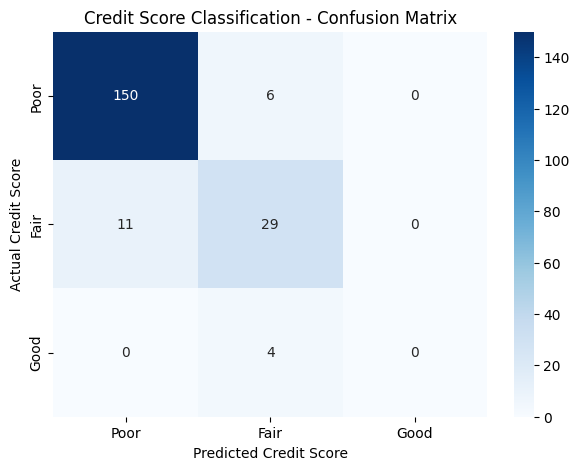


NEW CUSTOMER DETAILS
   Age  Annual_Income  Loan_Amount  Credit_Utilization  Payment_History  \
0   30         800000       200000                 0.3               11   

   Existing_Loans  Employment_Years  
0               1                 6  

Predicted Credit Score Category: Fair


In [1]:

# CREDIT SCORE CLASSIFICATION USING MACHINE LEARNING

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Step 2: Generate a sample credit score dataset
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    'Age': np.random.randint(21, 65, n),
    'Annual_Income': np.random.randint(200000, 1500000, n),
    'Loan_Amount': np.random.randint(10000, 800000, n),
    'Credit_Utilization': np.random.uniform(0.05, 1.0, n),
    'Payment_History': np.random.randint(0, 13, n),
    'Existing_Loans': np.random.randint(0, 6, n),
    'Employment_Years': np.random.randint(0, 30, n)
})

# Step 3: Assign credit score based on sample rules
credit_score = (
    300
    + (data['Annual_Income'] / 1500000) * 180
    + (1 - data['Credit_Utilization']) * 120
    + (data['Payment_History'] / 12) * 150
    + (data['Employment_Years'] / 30) * 50
    + (data['Age'] / 65) * 30
    - (data['Loan_Amount'] / 800000) * 70
    - data['Existing_Loans'] * 10
)

# Step 4: Convert credit scores into classes
data['Credit_Score'] = pd.cut(
    credit_score,
    bins=[-np.inf, 580, 670, np.inf],
    labels=['Poor', 'Fair', 'Good']
)

print("CREDIT SCORE DATASET")
print(data.head())

print("\nClass Distribution:")
print(data['Credit_Score'].value_counts())

# Step 5: Separate input and output variables
X = data.drop('Credit_Score', axis=1)
y = data['Credit_Score']

# Step 6: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 7: Create and train the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 8: Predict credit score
y_pred = model.predict(X_test)

print("\nPredicted Credit Scores:")
print(y_pred[:10])

print("\nActual Credit Scores:")
print(y_test.iloc[:10].values)

# Step 9: Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 10: Display classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

# Step 11: Display confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Poor', 'Fair', 'Good']
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Poor', 'Fair', 'Good'],
    yticklabels=['Poor', 'Fair', 'Good']
)

plt.xlabel("Predicted Credit Score")
plt.ylabel("Actual Credit Score")
plt.title("Credit Score Classification - Confusion Matrix")
plt.show()

# Step 12: Predict credit score for a new customer
new_customer = pd.DataFrame([{
    'Age': 30,
    'Annual_Income': 800000,
    'Loan_Amount': 200000,
    'Credit_Utilization': 0.30,
    'Payment_History': 11,
    'Existing_Loans': 1,
    'Employment_Years': 6
}])

prediction = model.predict(new_customer)

print("\nNEW CUSTOMER DETAILS")
print(new_customer)

print("\nPredicted Credit Score Category:", prediction[0])
